# Assignment 3: Image Generation with a GAN

1. **Practice: GAN Architecture** – implement the specified Generator and Discriminator in PyTorch.
2. **Practice: Model Deployment** – train the GAN on MNIST and add it to the API (`GET /generate`).
3. **Theory: Building Blocks of GAN** – Questions 1–7 with all work shown.

The GAN code lives in the helper library from the Module 6 Class Activity:

| File | Content |
|------|---------|
| `helper_lib/model.py` | `Generator`, `Discriminator`, `GAN` and `get_model("GAN")` |
| `helper_lib/trainer.py` | `train_gan(...)` |
| `helper_lib/generator.py` | `generate_samples(...)` |
| `helper_lib/data_loader.py` | `get_data_loader(...)` (MNIST, normalized to [-1, 1]) |

GitHub repository: https://github.com/yuchienchen0930/5560-api-project

In [1]:
import helper_lib  # sets KMP_DUPLICATE_LIB_OK before torch is imported (Windows/Anaconda OpenMP fix)
import inspect
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from helper_lib.model import get_model, Generator, Discriminator
from helper_lib.data_loader import get_data_loader
from helper_lib.trainer import train_gan
from helper_lib.generator import generate_samples

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


## Part 1: GAN Architecture

### Generator

| Layer | Output shape |
|-------|--------------|
| Input: noise vector | (N, 100) |
| Linear 100 → 7·7·128, reshape | (N, 128, 7, 7) |
| ConvTranspose2d 128 → 64, k=4, s=2, p=1 + BatchNorm2d + ReLU | (N, 64, 14, 14) |
| ConvTranspose2d 64 → 1, k=4, s=2, p=1 + Tanh | (N, 1, 28, 28) |

Transposed convolution output size: $O = (I - 1)S - 2P + K$
- Deconv1: $(7 - 1)\cdot 2 - 2\cdot1 + 4 = 14$
- Deconv2: $(14 - 1)\cdot 2 - 2\cdot1 + 4 = 28$

Tanh keeps the output in $[-1, 1]$, matching the MNIST images normalized with `Normalize((0.5,), (0.5,))`.

### Discriminator

| Layer | Output shape |
|-------|--------------|
| Input: image | (N, 1, 28, 28) |
| Conv2d 1 → 64, k=4, s=2, p=1 + LeakyReLU(0.2) | (N, 64, 14, 14) |
| Conv2d 64 → 128, k=4, s=2, p=1 + BatchNorm2d + LeakyReLU(0.2) | (N, 128, 7, 7) |
| Flatten + Linear 6272 → 1 | (N, 1) |

Convolution output size: $O = \lfloor (I + 2P - K)/S \rfloor + 1$
- Conv1: $(28 + 2 - 4)/2 + 1 = 14$
- Conv2: $(14 + 2 - 4)/2 + 1 = 7$

The final Linear layer outputs a logit; the real/fake probability is $\sigma(\text{logit})$. The sigmoid is applied inside
`BCEWithLogitsLoss` during training, which is numerically more stable than a separate Sigmoid layer.

In [2]:
print(inspect.getsource(Generator))
print(inspect.getsource(Discriminator))

class Generator(nn.Module):
    def __init__(self, z_dim=100):
        super().__init__()
        self.z_dim = z_dim
        self.fc = nn.Linear(z_dim, 7 * 7 * 128)                                     # (N, 100) -> (N, 6272)
        self.deconv1 = nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1)  # 7x7 -> 14x14
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(True)
        self.deconv2 = nn.ConvTranspose2d(64, 1, kernel_size=4, stride=2, padding=1)    # 14x14 -> 28x28
        self.tanh = nn.Tanh()

    def forward(self, z):
        x = self.fc(z.view(z.size(0), -1))
        x = x.view(-1, 128, 7, 7)
        x = self.relu(self.bn1(self.deconv1(x)))
        return self.tanh(self.deconv2(x))

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1)    # 28x28 -> 14x14
        self.act1 = nn.LeakyReLU(0.2, inplace=True)
        self.conv2 = nn.Conv2d(64, 128, 

In [3]:
gan = get_model("GAN").to(device)
G, D = gan.generator, gan.discriminator

z = torch.randn(1, 100, device=device)
print("Generator")
print("  input noise:      ", tuple(z.shape))
x = G.fc(z);                          print("  Linear:           ", tuple(x.shape))
x = x.view(-1, 128, 7, 7);            print("  reshape:          ", tuple(x.shape))
x = G.relu(G.bn1(G.deconv1(x)));      print("  Deconv1+BN+ReLU:  ", tuple(x.shape))
x = G.tanh(G.deconv2(x));             print("  Deconv2+Tanh:     ", tuple(x.shape))

print("Discriminator")
y = D.act1(D.conv1(x));               print("  Conv1+LeakyReLU:  ", tuple(y.shape))
y = D.act2(D.bn2(D.conv2(y)));        print("  Conv2+BN+LeakyReLU:", tuple(y.shape))
y = D.fc(D.flatten(y));               print("  Flatten+Linear:   ", tuple(y.shape))

count = lambda m: sum(p.numel() for p in m.parameters() if p.requires_grad)
print(f"\nGenerator parameters:     {count(G):,}")
print(f"Discriminator parameters: {count(D):,}")

Generator
  input noise:       (1, 100)
  Linear:            (1, 6272)
  reshape:           (1, 128, 7, 7)
  Deconv1+BN+ReLU:   (1, 64, 14, 14)
  Deconv2+Tanh:      (1, 1, 28, 28)
Discriminator
  Conv1+LeakyReLU:   (1, 64, 14, 14)
  Conv2+BN+LeakyReLU: (1, 128, 7, 7)
  Flatten+Linear:    (1, 1)

Generator parameters:     765,761
Discriminator parameters: 138,817


## Part 2: Model Deployment

### 2.1 Load MNIST
Pixels are normalized to $[-1, 1]$ so that real images have the same range as the generator's Tanh output.

Training batches: 469 | batch shape: (128, 1, 28, 28) | pixel range: (-1.0, 1.0)


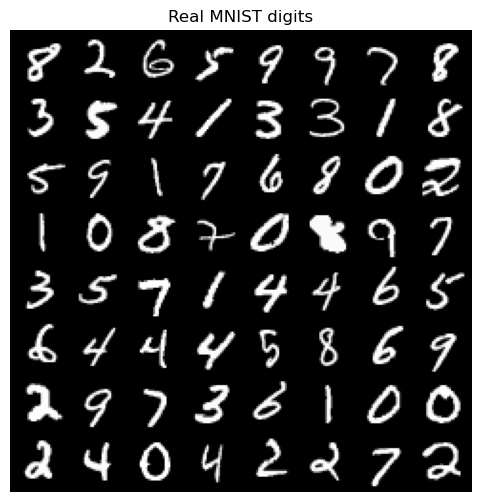

In [4]:
train_loader = get_data_loader("data", batch_size=128, train=True)
real, _ = next(iter(train_loader))
print("Training batches:", len(train_loader), "| batch shape:", tuple(real.shape),
      "| pixel range:", (real.min().item(), real.max().item()))

from torchvision.utils import make_grid
plt.figure(figsize=(6, 6))
plt.imshow(make_grid((real[:64] + 1) / 2, nrow=8).permute(1, 2, 0))
plt.title("Real MNIST digits"); plt.axis("off"); plt.show()

### 2.2 Train the GAN

Standard GAN objective with binary cross-entropy:

$$
\mathcal{L}_D = -\left[\log D(x) + \log(1 - D(G(z)))\right], \qquad
\mathcal{L}_G = -\log D(G(z))
$$

Each batch first updates the Discriminator on real images (label 1) and generated images (label 0), then updates the
Generator so that the Discriminator labels its images as real. Optimizer: Adam (lr = 0.0002, β₁ = 0.5) for both networks, 15 epochs.

In [5]:
gan = train_gan(gan, train_loader, criterion=nn.BCEWithLogitsLoss(), device=device, epochs=15)

Epoch 1/15 | D loss 0.3853 | G loss 2.1864 | D(x) 0.842 | D(G(z)) 0.163


Epoch 2/15 | D loss 0.3625 | G loss 2.4205 | D(x) 0.857 | D(G(z)) 0.143


Epoch 3/15 | D loss 0.3546 | G loss 2.4654 | D(x) 0.859 | D(G(z)) 0.141


Epoch 4/15 | D loss 0.3932 | G loss 2.4139 | D(x) 0.848 | D(G(z)) 0.152


Epoch 5/15 | D loss 0.3825 | G loss 2.4463 | D(x) 0.850 | D(G(z)) 0.150


Epoch 6/15 | D loss 0.3785 | G loss 2.4979 | D(x) 0.854 | D(G(z)) 0.147


... (5 outputs left out)

Epoch 12/15 | D loss 0.3393 | G loss 2.9192 | D(x) 0.877 | D(G(z)) 0.123


Epoch 13/15 | D loss 0.2784 | G loss 3.0412 | D(x) 0.892 | D(G(z)) 0.108


Epoch 14/15 | D loss 0.2753 | G loss 3.1609 | D(x) 0.895 | D(G(z)) 0.105


Epoch 15/15 | D loss 0.2710 | G loss 3.2191 | D(x) 0.897 | D(G(z)) 0.103


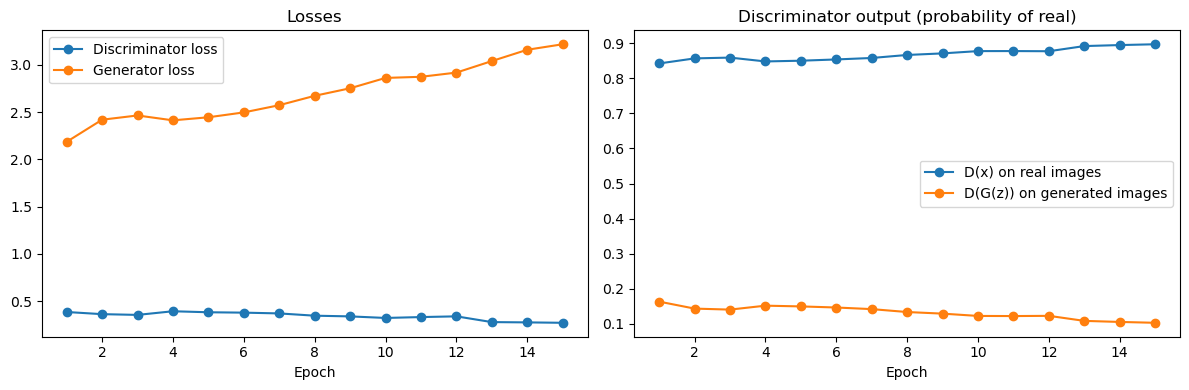

In [6]:
h = gan.history
ep = range(1, len(h["d_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ep, h["d_loss"], marker="o", label="Discriminator loss")
axes[0].plot(ep, h["g_loss"], marker="o", label="Generator loss")
axes[0].set_xlabel("Epoch"); axes[0].set_title("Losses"); axes[0].legend()
axes[1].plot(ep, h["d_real"], marker="o", label="D(x) on real images")
axes[1].plot(ep, h["d_fake"], marker="o", label="D(G(z)) on generated images")
axes[1].set_xlabel("Epoch"); axes[1].set_title("Discriminator output (probability of real)"); axes[1].legend()
plt.tight_layout(); plt.show()

### 2.3 Generate digits

`generate_samples` (from `helper_lib/generator.py`) samples random noise vectors, runs the Generator and plots the images on a grid.

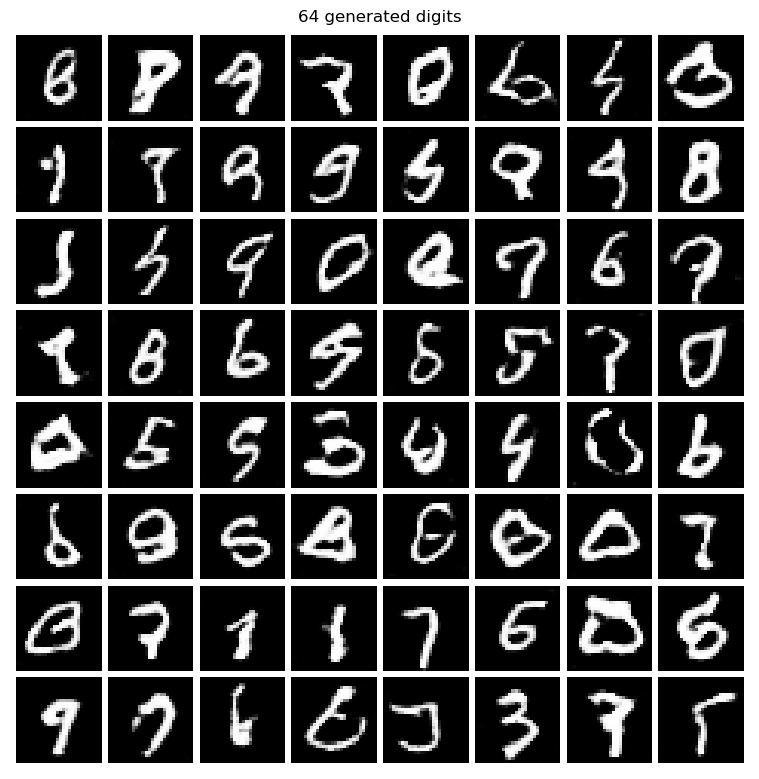

In [7]:
generate_samples(gan, device=device, num_samples=64, seed=0)

In [8]:
torch.save(gan.generator.state_dict(), "model/gan_generator.pth")
print("Saved generator weights to model/gan_generator.pth")

Saved generator weights to model/gan_generator.pth


### 2.4 Serve the GAN with FastAPI

`api/main.py` loads `model/gan_generator.pth` and adds:

| Method | Endpoint | Parameters | Output |
|--------|----------|------------|--------|
| GET | `/generate` | `num_samples` (1–100, default 16), optional `seed` | PNG image grid of generated digits |

Start the API from the project root and open http://127.0.0.1:8000/generate?num_samples=16 in a browser:

```
python -m uvicorn api.main:app --reload
```

The cell below calls the endpoint in-process and displays the returned PNG.

C:\Users\User\anaconda3\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


Status: 200 | Content-Type: image/png


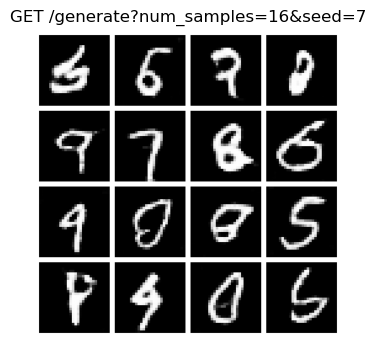

In [9]:
import io
from PIL import Image
from fastapi.testclient import TestClient
from api.main import app

client = TestClient(app)
resp = client.get("/generate", params={"num_samples": 16, "seed": 7})
print("Status:", resp.status_code, "| Content-Type:", resp.headers["content-type"])
img = Image.open(io.BytesIO(resp.content))
plt.figure(figsize=(4, 4)); plt.imshow(img, cmap="gray"); plt.axis("off")
plt.title("GET /generate?num_samples=16&seed=7"); plt.show()

## Part 3: Theory – Building Blocks of GAN

### Question 1
*8×8 input, transposed convolution with kernel 4×4, stride 2, padding 1, output padding 1.*

Formula (Question 3): $O = (I - 1)\times S - 2P + K + OP$

$$
O = (8 - 1)\times 2 - 2(1) + 4 + 1 = 14 - 2 + 4 + 1 = 17
$$

**Answer: 17 × 17** (the same calculation applies to height and width).

### Question 2
*Increase the stride from 2 to 3, everything else fixed.*

The stride multiplies $(I - 1)$, so each extra unit of stride adds $(I - 1)$ to the output size:

$$
\Delta O = (I - 1)(S_{new} - S_{old}) = (8 - 1)(3 - 2) = 7
$$

With the settings of Question 1: $O = (8 - 1)\times 3 - 2(1) + 4 + 1 = 21 - 2 + 4 + 1 = 24$.

**Answer:** the output grows from 17 × 17 to **24 × 24**. Increasing the stride inserts more space between the input
positions, so the output becomes larger. Roughly, the output is about $S$ times the input ($8 \to 16$ for $S = 2$, $8 \to 24$ for $S = 3$).
Output padding must stay smaller than the stride, so $OP = 1$ is still valid.

### Question 3
*Output size of a 2D transposed convolution.*

$$
O = (I - 1)\times S - 2P + K + OP
$$

(with dilation $d$, the kernel term becomes $d(K - 1) + 1$; for $d = 1$ this is $K$). Applied separately to height and width.

### Question 4
*Upsample 16×16 → 32×32 with no padding.*

With $P = 0$ and $OP = 0$: $32 = (16 - 1)\times S + K = 15S + K$.

- $S = 2$: $32 = 30 + K \Rightarrow K = 2$

**Answer: kernel size 2×2, stride 2** (padding 0): $(16 - 1)\times 2 - 0 + 2 = 32$.

### Question 5
*BatchNorm (no γ, β) on the mini-batch [6, 8, 10, 6].*

$\hat{x}_i = \dfrac{x_i - \mu}{\sqrt{\sigma^2 + \epsilon}}$, where BatchNorm uses the batch mean and the biased (population) variance.

1. Mean: $\mu = \frac{6 + 8 + 10 + 6}{4} = \frac{30}{4} = 7.5$
2. Deviations: $6 - 7.5 = -1.5,\; 8 - 7.5 = 0.5,\; 10 - 7.5 = 2.5,\; 6 - 7.5 = -1.5$
3. Variance: $\sigma^2 = \frac{(-1.5)^2 + 0.5^2 + 2.5^2 + (-1.5)^2}{4} = \frac{2.25 + 0.25 + 6.25 + 2.25}{4} = \frac{11}{4} = 2.75$
4. Standard deviation: $\sigma = \sqrt{2.75} \approx 1.6583$ (ε ≈ 10⁻⁵ is negligible)
5. Normalize:
   - $-1.5 / 1.6583 \approx -0.9045$
   - $0.5 / 1.6583 \approx 0.3015$
   - $2.5 / 1.6583 \approx 1.5076$
   - $-1.5 / 1.6583 \approx -0.9045$

**Answer: [−0.9045, 0.3015, 1.5076, −0.9045]** (mean 0, variance 1).

### Question 6
*ReLU vs LeakyReLU.*

$$
\text{ReLU}(x) = \max(0, x) = \begin{cases} x & x > 0 \\ 0 & x \le 0 \end{cases}
\qquad
\text{LeakyReLU}(x) = \begin{cases} x & x > 0 \\ \alpha x & x \le 0 \end{cases} = \max(\alpha x, x)
$$

with a small slope $\alpha$ (e.g. 0.01, or 0.2 in our Discriminator).

**Key difference:** for negative inputs ReLU outputs 0 and its gradient is 0, while LeakyReLU outputs $\alpha x$ and has
gradient $\alpha$. Derivatives: $\text{ReLU}'(x) \in \{0, 1\}$, $\text{LeakyReLU}'(x) \in \{\alpha, 1\}$.

### Question 7
*Why LeakyReLU might be preferred over ReLU in deep networks.*

- **Avoids "dying ReLU" neurons.** With ReLU, a neuron whose input is always negative outputs 0 and gets zero gradient, so
  its weights never update again. LeakyReLU always has a gradient of at least $\alpha$, so such neurons can recover.
- **Better gradient flow.** Gradients pass through negative activations as well, which helps signals propagate
  through many layers and makes training of deep networks more stable.
- **Keeps information from negative inputs**, and the activations are less biased toward positive values (mean closer to 0).
- **In GANs specifically**, the Generator is trained only through the Discriminator's gradients. LeakyReLU in the Discriminator
  makes sure useful gradients reach the Generator even for inputs that produce negative activations, which is why
  DCGAN-style discriminators (including the one in Part 1) use LeakyReLU(0.2).

### Verifying the answers with PyTorch

In [10]:
def out_hw(layer, h):
    return tuple(layer(torch.randn(1, 1, h, h)).shape[2:])

print("Q1:", out_hw(nn.ConvTranspose2d(1, 1, kernel_size=4, stride=2, padding=1, output_padding=1), 8), "-> 17x17")
print("Q2:", out_hw(nn.ConvTranspose2d(1, 1, kernel_size=4, stride=3, padding=1, output_padding=1), 8), "-> 24x24")
print("Q4:", out_hw(nn.ConvTranspose2d(1, 1, kernel_size=2, stride=2, padding=0), 16), "-> 32x32")

bn = nn.BatchNorm1d(1, affine=False)   # no gamma / beta
bn.train()
x = torch.tensor([[6.], [8.], [10.], [6.]])
print("Q5:", bn(x).squeeze().numpy().round(4))

v = torch.tensor([-3., -1., 0., 2.])
print("Q6: ReLU     ", nn.ReLU()(v).numpy())
print("    LeakyReLU", nn.LeakyReLU(0.2)(v).numpy())

Q1: (17, 17) -> 17x17
Q2: (24, 24) -> 24x24
Q4: (32, 32) -> 32x32
Q5: [-0.9045  0.3015  1.5076 -0.9045]
Q6: ReLU      [0. 0. 0. 2.]
    LeakyReLU [-0.6 -0.2  0.   2. ]


## Summary

- **Part 1:** Generator (100 → 7×7×128 → 14×14×64 → 28×28×1) and Discriminator (28×28×1 → 14×14×64 → 7×7×128 → 1)
  implemented exactly as specified, added to `helper_lib` and available through `get_model("GAN")`.
- **Part 2:** Trained on MNIST for 15 epochs; the generator produces recognizable handwritten digits and is served by
  `GET /generate` in the FastAPI app. Code committed to GitHub.
- **Part 3:** Q1 17×17 · Q2 24×24 (+7) · Q3 $O=(I-1)S-2P+K+OP$ · Q4 K=2, S=2 · Q5 [−0.9045, 0.3015, 1.5076, −0.9045] ·
  Q6/Q7 LeakyReLU keeps a small slope α for negative inputs, avoiding dead neurons and improving gradient flow.